In [17]:
#1.Import files
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

In [18]:
#2. Load dataset and find out summary
df = pd.read_csv('house_prices.csv')
print(df.head())
print(df.tail())
print(df.dtypes)
print(df.describe)
print(df.info())
print(df.shape)

           id             date     price  bedrooms  bathrooms  sqft_living  \
0  7129300520  20141013T000000  221900.0         3       1.00         1180   
1  6414100192  20141209T000000  538000.0         3       2.25         2570   
2  5631500400  20150225T000000  180000.0         2       1.00          770   
3  2487200875  20141209T000000  604000.0         4       3.00         1960   
4  1954400510  20150218T000000  510000.0         3       2.00         1680   

   sqft_lot  floors waterfront  view  ... grade  sqft_above  sqft_basement  \
0      5650     1.0          N     0  ...     7        1180              0   
1      7242     2.0          N     0  ...     7        2170            400   
2     10000     1.0          N     0  ...     6         770              0   
3      5000     1.0          N     0  ...     7        1050            910   
4      8080     1.0          N     0  ...     8        1680              0   

   yr_built  yr_renovated  zipcode      lat     long  sqft_liv

In [19]:
#3.Identifying independent and dependant variables
# Convert categorical text columns to numbers
y = df['price']
X = df.drop(columns = ['price','id','date'])
X = pd.get_dummies(X,columns = ['waterfront','condition'],drop_first = 'True')
print(X.head())

   bedrooms  bathrooms  sqft_living  sqft_lot  floors  view  grade  \
0         3       1.00         1180      5650     1.0     0      7   
1         3       2.25         2570      7242     2.0     0      7   
2         2       1.00          770     10000     1.0     0      6   
3         4       3.00         1960      5000     1.0     0      7   
4         3       2.00         1680      8080     1.0     0      8   

   sqft_above  sqft_basement  yr_built  ...  zipcode      lat     long  \
0        1180              0      1955  ...    98178  47.5112 -122.257   
1        2170            400      1951  ...    98125  47.7210 -122.319   
2         770              0      1933  ...    98028  47.7379 -122.233   
3        1050            910      1965  ...    98136  47.5208 -122.393   
4        1680              0      1987  ...    98074  47.6168 -122.045   

   sqft_living15  sqft_lot15  waterfront_Y  condition_Fair  condition_Good  \
0           1340        5650         False           Fal

In [20]:
#4.Split the data into training and testing sets
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size = 0.2,random_state = 42 )

In [21]:
#5.Feature scale larger numerical range features to dominate small scale features
#never call fit on testing data as it causes data leakage
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [22]:
#6.Training the model
#Baseline Linear Regression
linear_model = LinearRegression()
linear_model.fit(X_train_scaled,y_train)
#Random Forest Regressor
randomforest_model = RandomForestRegressor(n_estimators = 100,random_state = 42,n_jobs = -1)
randomforest_model.fit(X_train,y_train)

RandomForestRegressor(n_jobs=-1, random_state=42)

In [23]:
#7.Testing and Evaulation of both models
y_true = y_test
linear_pred = linear_model.predict(X_test_scaled)

mae = mean_absolute_error(y_true,linear_pred)
mse = mean_squared_error(y_true,linear_pred)
rmse = np.sqrt(mse)
r2score = r2_score(y_true,linear_pred)

print("Linear Regression")
print("Mean Absolute Error",mae)
print("Mean Squared Error",mse)
print("Root Mean Sqaured Error",rmse)
print("R2 Score",r2score)
print()
randomforest_pred = randomforest_model.predict(X_test)

mae = mean_absolute_error(y_true,randomforest_pred)
mse = mean_squared_error(y_true,randomforest_pred)
rmse = np.sqrt(mse)
r2score = r2_score(y_true,randomforest_pred)

print("Random Forest")
print("Mean Absolute Error",mae)
print("Mean Squared Error",mse)
print("Root Mean Sqaured Error",rmse)
print("R2 Score",r2score)

Linear Regression
Mean Absolute Error 127384.62633631118
Mean Squared Error 45125699163.54038
Root Mean Sqaured Error 212428.10351632003
R2 Score 0.701503634456148

Random Forest
Mean Absolute Error 73133.30570415441
Mean Squared Error 22421637930.7983
Root Mean Sqaured Error 149738.56527561063
R2 Score 0.8516859005856481


In [24]:
#8.Inspecting Features Importances

importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': randomforest_model.feature_importances_
}).sort_values(by='Importance', ascending=False)

print(importance_df)

                Feature  Importance
6                 grade    0.314357
2           sqft_living    0.274885
12                  lat    0.153276
13                 long    0.063367
9              yr_built    0.033143
16         waterfront_Y    0.031710
14        sqft_living15    0.031165
7            sqft_above    0.019567
11              zipcode    0.014582
3              sqft_lot    0.013853
15           sqft_lot15    0.012445
1             bathrooms    0.011247
5                  view    0.010237
8         sqft_basement    0.006325
0              bedrooms    0.003330
10         yr_renovated    0.002151
4                floors    0.001883
18       condition_Good    0.001118
20  condition_Very Good    0.001025
17       condition_Fair    0.000241
19       condition_Poor    0.000096


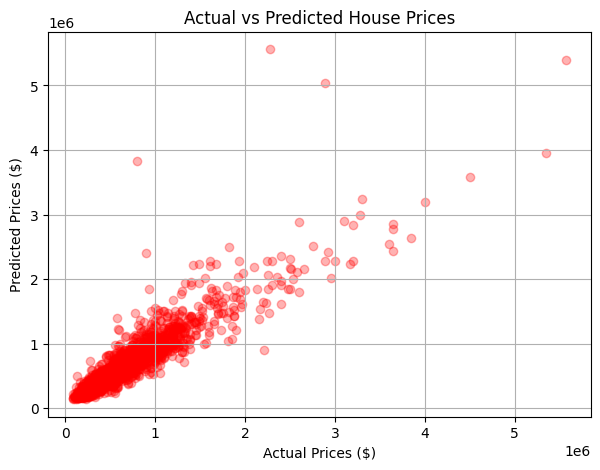

In [25]:
#9.Actual Prices Vs. Predicted Prices

plt.figure(figsize = (7,5))
plt.scatter(y_test,randomforest_pred,alpha = 0.3,color = 'red')
plt.title("Actual vs Predicted House Prices")
plt.xlabel("Actual Prices ($)")
plt.ylabel("Predicted Prices ($)")
plt.grid(True)
plt.show()

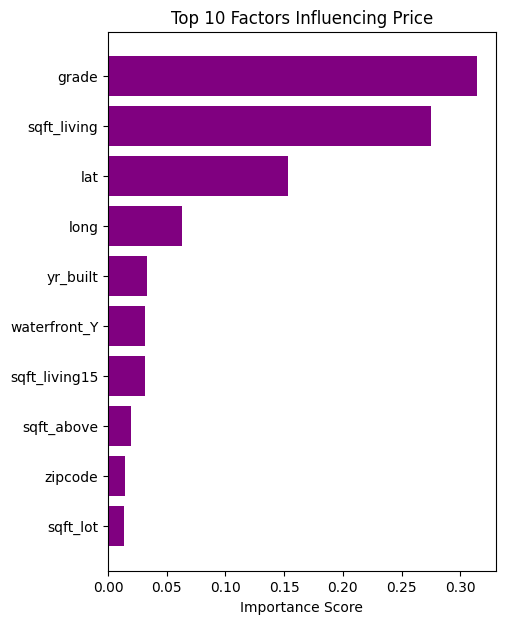

In [26]:
#10. Top 10 Most Important Features
# Grab the top 10 features from your existing importance_df
top_10 = importance_df.head(10)

# Create a horizontal bar chart
plt.figure(figsize = (5,7))
plt.barh(top_10['Feature'],top_10['Importance'],color = 'purple')

# Flip the chart so the #1 feature is at the top
plt.gca().invert_yaxis()

# Add labels and display
plt.title("Top 10 Factors Influencing Price")
plt.xlabel("Importance Score")
plt.show()